# 03: Uplift Modeling & Campaign Economics

**RetentionIQ Portfolio Showcase** | Dataset: *Criteo Uplift v2.1*

> **Synthetic data.** This notebook runs on `data/sample/`, generated with a seeded random generator by `scripts/make_sample.py` to mimic the real schema. It is **not** a sample of the real dataset: outputs demonstrate the method, not real findings. Real results: `docs/RESULTS.md`.

This notebook demonstrates causal machine learning for targeted ad retargeting:
1. **Randomized Trial Validation**: Verifying balance with Standardized Mean Differences (SMD).
2. **The 'Likely Converter' Trap**: Why response propensity wastes ad spend on natural buyers ('always-takers').
3. **CATE Meta-Learners**: Estimating individual treatment effects via Two-Model and cross-fitted X-Learner.
4. **Qini Curve & Decile Uplift Calibration**: Verifying monotonic sorting of incremental conversions.
5. **Campaign Reach Optimization**: Pinpointing the profit-optimal audience reach under real unit economics.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from retentioniq.analytics.experiments.inference import standardized_mean_differences, compare_arms
from retentioniq.models.uplift.learners import ResponseModel, TwoModel, XLearner
from retentioniq.models.uplift.metrics import qini_curve, qini_coefficient, uplift_by_score_decile, top_k_counts

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
cb_blue, cb_orange, cb_green = '#1f77b4', '#ff7f0e', '#2ca02c'

# Load sample dataset
sample_path = Path('data/sample/criteo_sample.parquet')
if not sample_path.exists():
    sample_path = Path('../data/sample/criteo_sample.parquet')
df = pd.read_parquet(sample_path)
print(f'Loaded {len(df):,} experiment rows (treatment share: {df["treatment"].mean():.2%}).')
df.head(3)

Loaded 50,000 experiment rows (treatment share: 85.34%).


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,visit,conversion,exposure
0,-0.964737,-1.281566,0.293058,-0.537086,0.742213,-1.177650,0.681609,-1.369777,1.108747,0.657237,-0.170078,-0.716962,1,0,0,1
1,-0.685523,1.365821,0.479552,0.014376,-1.485203,0.344454,0.104999,-0.120132,0.416534,-0.168038,-0.703693,-1.412354,1,0,0,1
2,-1.792758,0.306470,-0.179700,1.259058,0.214633,-0.504747,0.940803,0.951770,-2.045319,-0.131046,-1.458707,2.099101,1,0,0,1


## 1. Randomization Checks & Covariate Balance

In randomized controlled trials, pre-treatment covariates must be balanced across arms. A standard threshold is $|\text{SMD}| < 0.10$ for all features.

In [2]:
features = [f'f{i}' for i in range(12)]
t = df['treatment'].to_numpy()
smd = standardized_mean_differences(df[features], t)
print(f'Maximum Absolute SMD across 12 features: {smd.abs().max():.4f} (All < 0.10: {(smd.abs() < 0.10).all()})')

cmp_visit = compare_arms(df['visit'].to_numpy(), t, outcome='visit')
print(f'Overall Visit ATE: +{cmp_visit.ate:.4f} (Relative Lift: {cmp_visit.relative_lift:.1%}, p={cmp_visit.p_value:.2e})')

Maximum Absolute SMD across 12 features: 0.0244 (All < 0.10: True)
Overall Visit ATE: +0.0114 (Relative Lift: 27.8%, p=3.93e-05)


## 2. Fitting CATE Estimators vs Response Model

We split into train and test sets, then train:
- **Response Model**: standard propensity model predicting $P(Y=1 \mid X)$ (ignores treatment).
- **Two-Model (T-Learner)**: separate models for treated and control arms.
- **X-Learner**: 2-fold cross-fitted counterfactual imputation with propensity weighting.

In [3]:
train, test = train_test_split(df, test_size=0.3, random_state=42, stratify=df['treatment'])

resp_model = ResponseModel().fit(train, train['treatment'].to_numpy(), train['visit'].to_numpy())
two_model = TwoModel(name='two_model_lgbm').fit(train, train['treatment'].to_numpy(), train['visit'].to_numpy())
x_learner = XLearner().fit(train, train['treatment'].to_numpy(), train['visit'].to_numpy())

score_resp = resp_model.score(test)
score_two = two_model.score(test)
score_x = x_learner.score(test)

y_te, t_te = test['visit'].to_numpy(), test['treatment'].to_numpy()
q_resp = qini_coefficient(y_te, t_te, score_resp)
q_two = qini_coefficient(y_te, t_te, score_two)
q_x = qini_coefficient(y_te, t_te, score_x)
print(f'Response Model Normalized Qini: {q_resp:.4f}')
print(f'Two-Model LGBM Normalized Qini: {q_two:.4f}')
print(f'X-Learner Normalized Qini:      {q_x:.4f}')

Response Model Normalized Qini: 0.0970
Two-Model LGBM Normalized Qini: 0.0407
X-Learner Normalized Qini:      0.0133


## 3. Qini Curves & Decile Calibration

The Qini curve plots cumulative incremental outcomes as a function of the fraction of the population targeted.

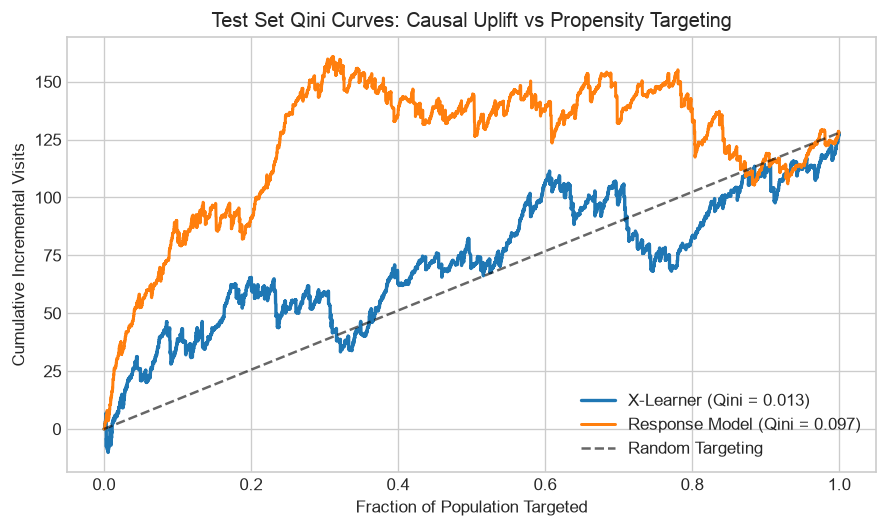

In [4]:
c_resp = qini_curve(y_te, t_te, score_resp)
c_x = qini_curve(y_te, t_te, score_x)

fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=120)
n_pts = len(c_x.depth)
ax.plot(c_x.depth / n_pts, c_x.value, label=f'X-Learner (Qini = {q_x:.3f})', color=cb_blue, linewidth=2)
ax.plot(c_resp.depth / n_pts, c_resp.value, label=f'Response Model (Qini = {q_resp:.3f})', color=cb_orange, linewidth=1.8)
ax.plot([0, 1], [0, c_x.value[-1]], 'k--', label='Random Targeting', alpha=0.6)
ax.set_xlabel('Fraction of Population Targeted')
ax.set_ylabel('Cumulative Incremental Visits')
ax.set_title('Test Set Qini Curves: Causal Uplift vs Propensity Targeting')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 4. Campaign Economic Simulation: Fine Reach Optimization

Targeting the entire population often turns negative-ROI. Under unit economics ($0.01 cost per impression, $10 per conversion), we compute net campaign profit from 1% to 50% reach to identify the profit-optimal stopping point.

X-Learner Profit-Optimal Reach: 49% (Max Net Profit: $239.36)


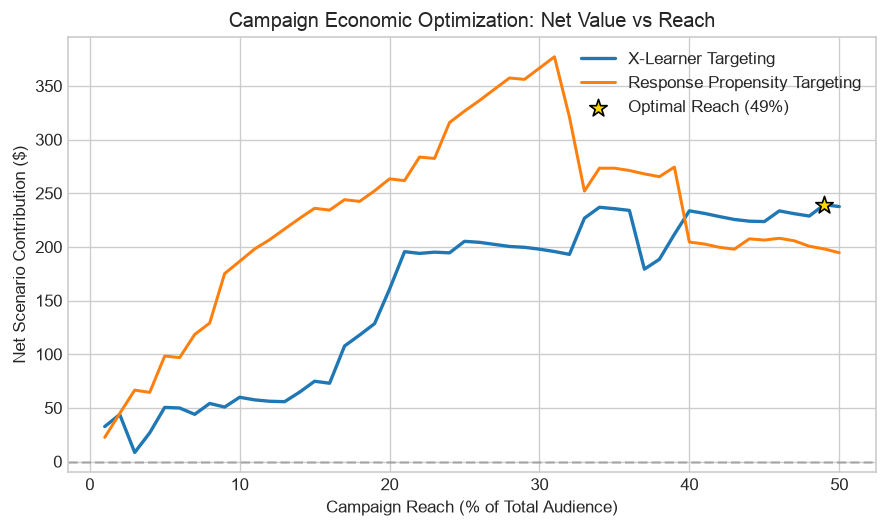

In [5]:
reaches = np.round(np.arange(0.01, 0.51, 0.01), 2)
cost_per_imp = 0.01
val_per_conv = 10.0
pop = len(test)
y_conv = test['conversion'].to_numpy()

profits_x, profits_resp = [], []
for r in reaches:
    # X-learner
    yt_x, nt_x, yc_x, nc_x = top_k_counts(y_conv, t_te, score_x, float(r))
    inc_x = (yt_x / nt_x - yc_x / nc_x) * (float(r) * pop) if nt_x and nc_x else 0.0
    profits_x.append(inc_x * val_per_conv - (float(r) * pop) * cost_per_imp)
    # Response model
    yt_r, nt_r, yc_r, nc_r = top_k_counts(y_conv, t_te, score_resp, float(r))
    inc_r = (yt_r / nt_r - yc_r / nc_r) * (float(r) * pop) if nt_r and nc_r else 0.0
    profits_resp.append(inc_r * val_per_conv - (float(r) * pop) * cost_per_imp)

opt_reach_x = reaches[int(np.argmax(profits_x))]
print(f'X-Learner Profit-Optimal Reach: {opt_reach_x:.0%} (Max Net Profit: ${max(profits_x):,.2f})')

fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=120)
ax.plot(reaches * 100, profits_x, label='X-Learner Targeting', color=cb_blue, linewidth=2)
ax.plot(reaches * 100, profits_resp, label='Response Propensity Targeting', color=cb_orange, linewidth=1.8)
ax.scatter([opt_reach_x * 100], [max(profits_x)], s=120, marker='*', color='gold', edgecolor='black', zorder=5, label=f'Optimal Reach ({opt_reach_x:.0%})')
ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax.set_xlabel('Campaign Reach (% of Total Audience)')
ax.set_ylabel('Net Scenario Contribution ($)')
ax.set_title('Campaign Economic Optimization: Net Value vs Reach')
ax.legend()
plt.tight_layout()
plt.show()